Initializing XAI Audit for Traditional Baselines...
Calculating TreeSHAP values for Random Forest...


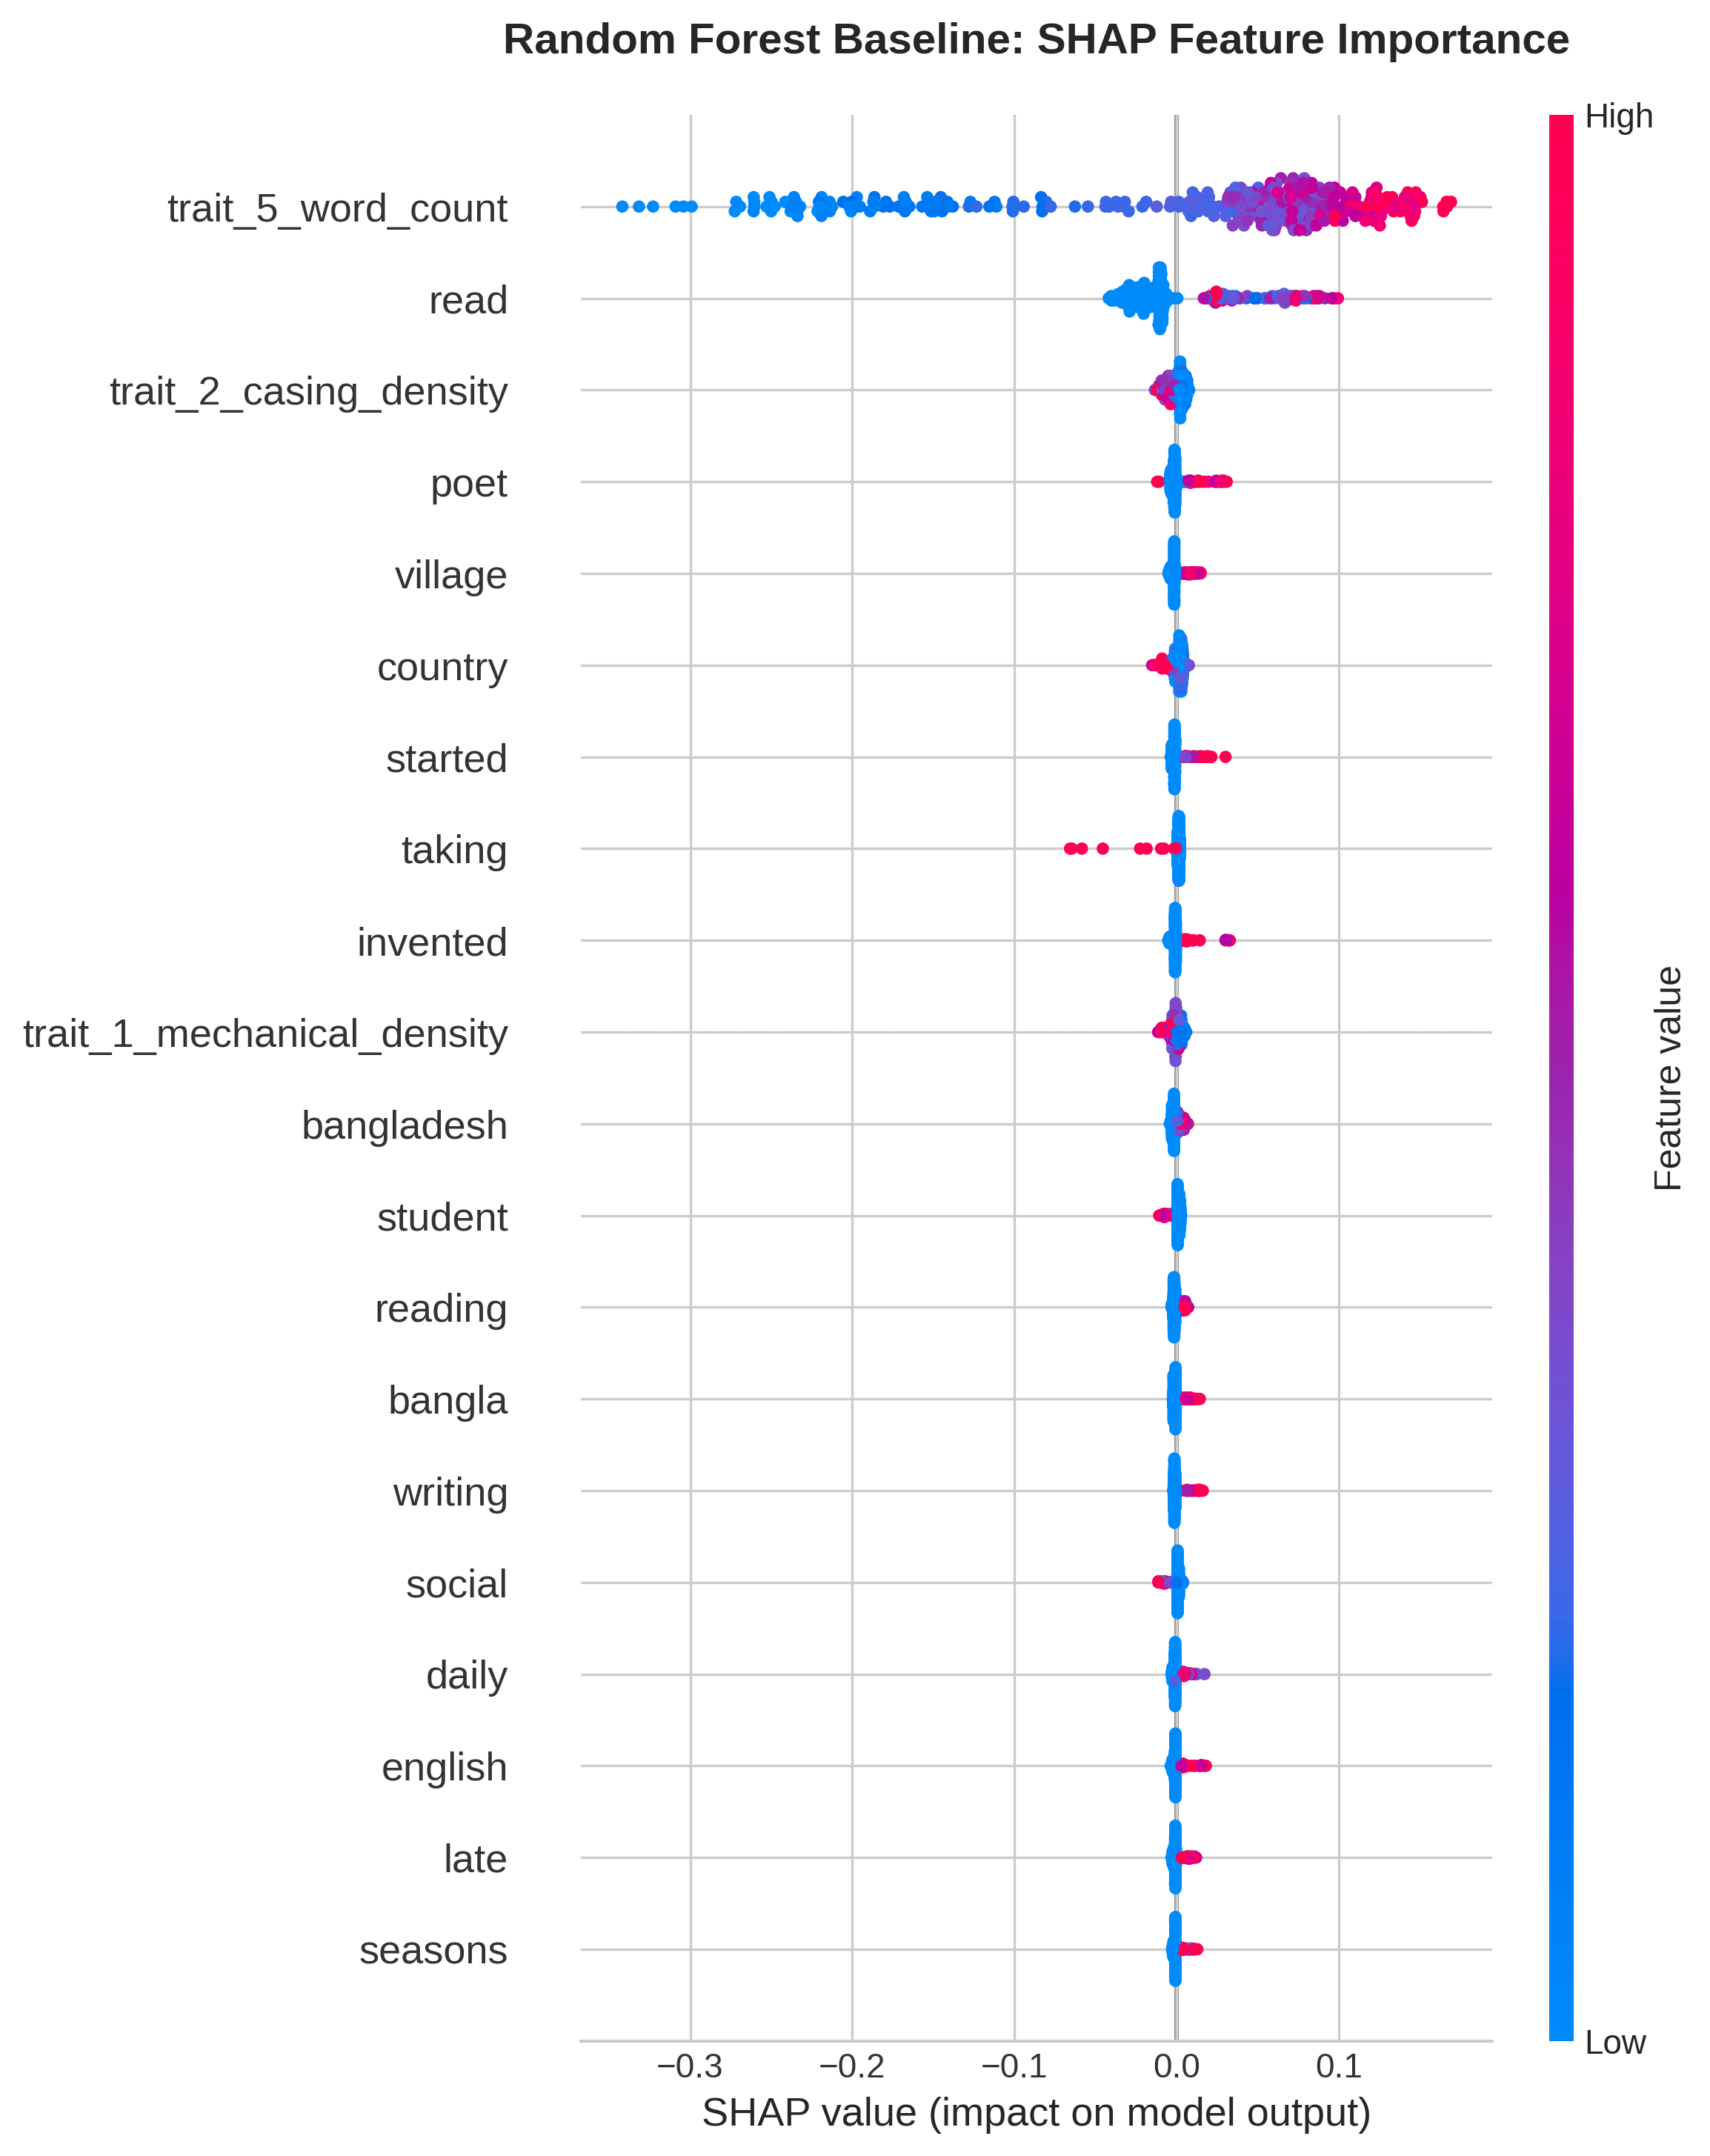

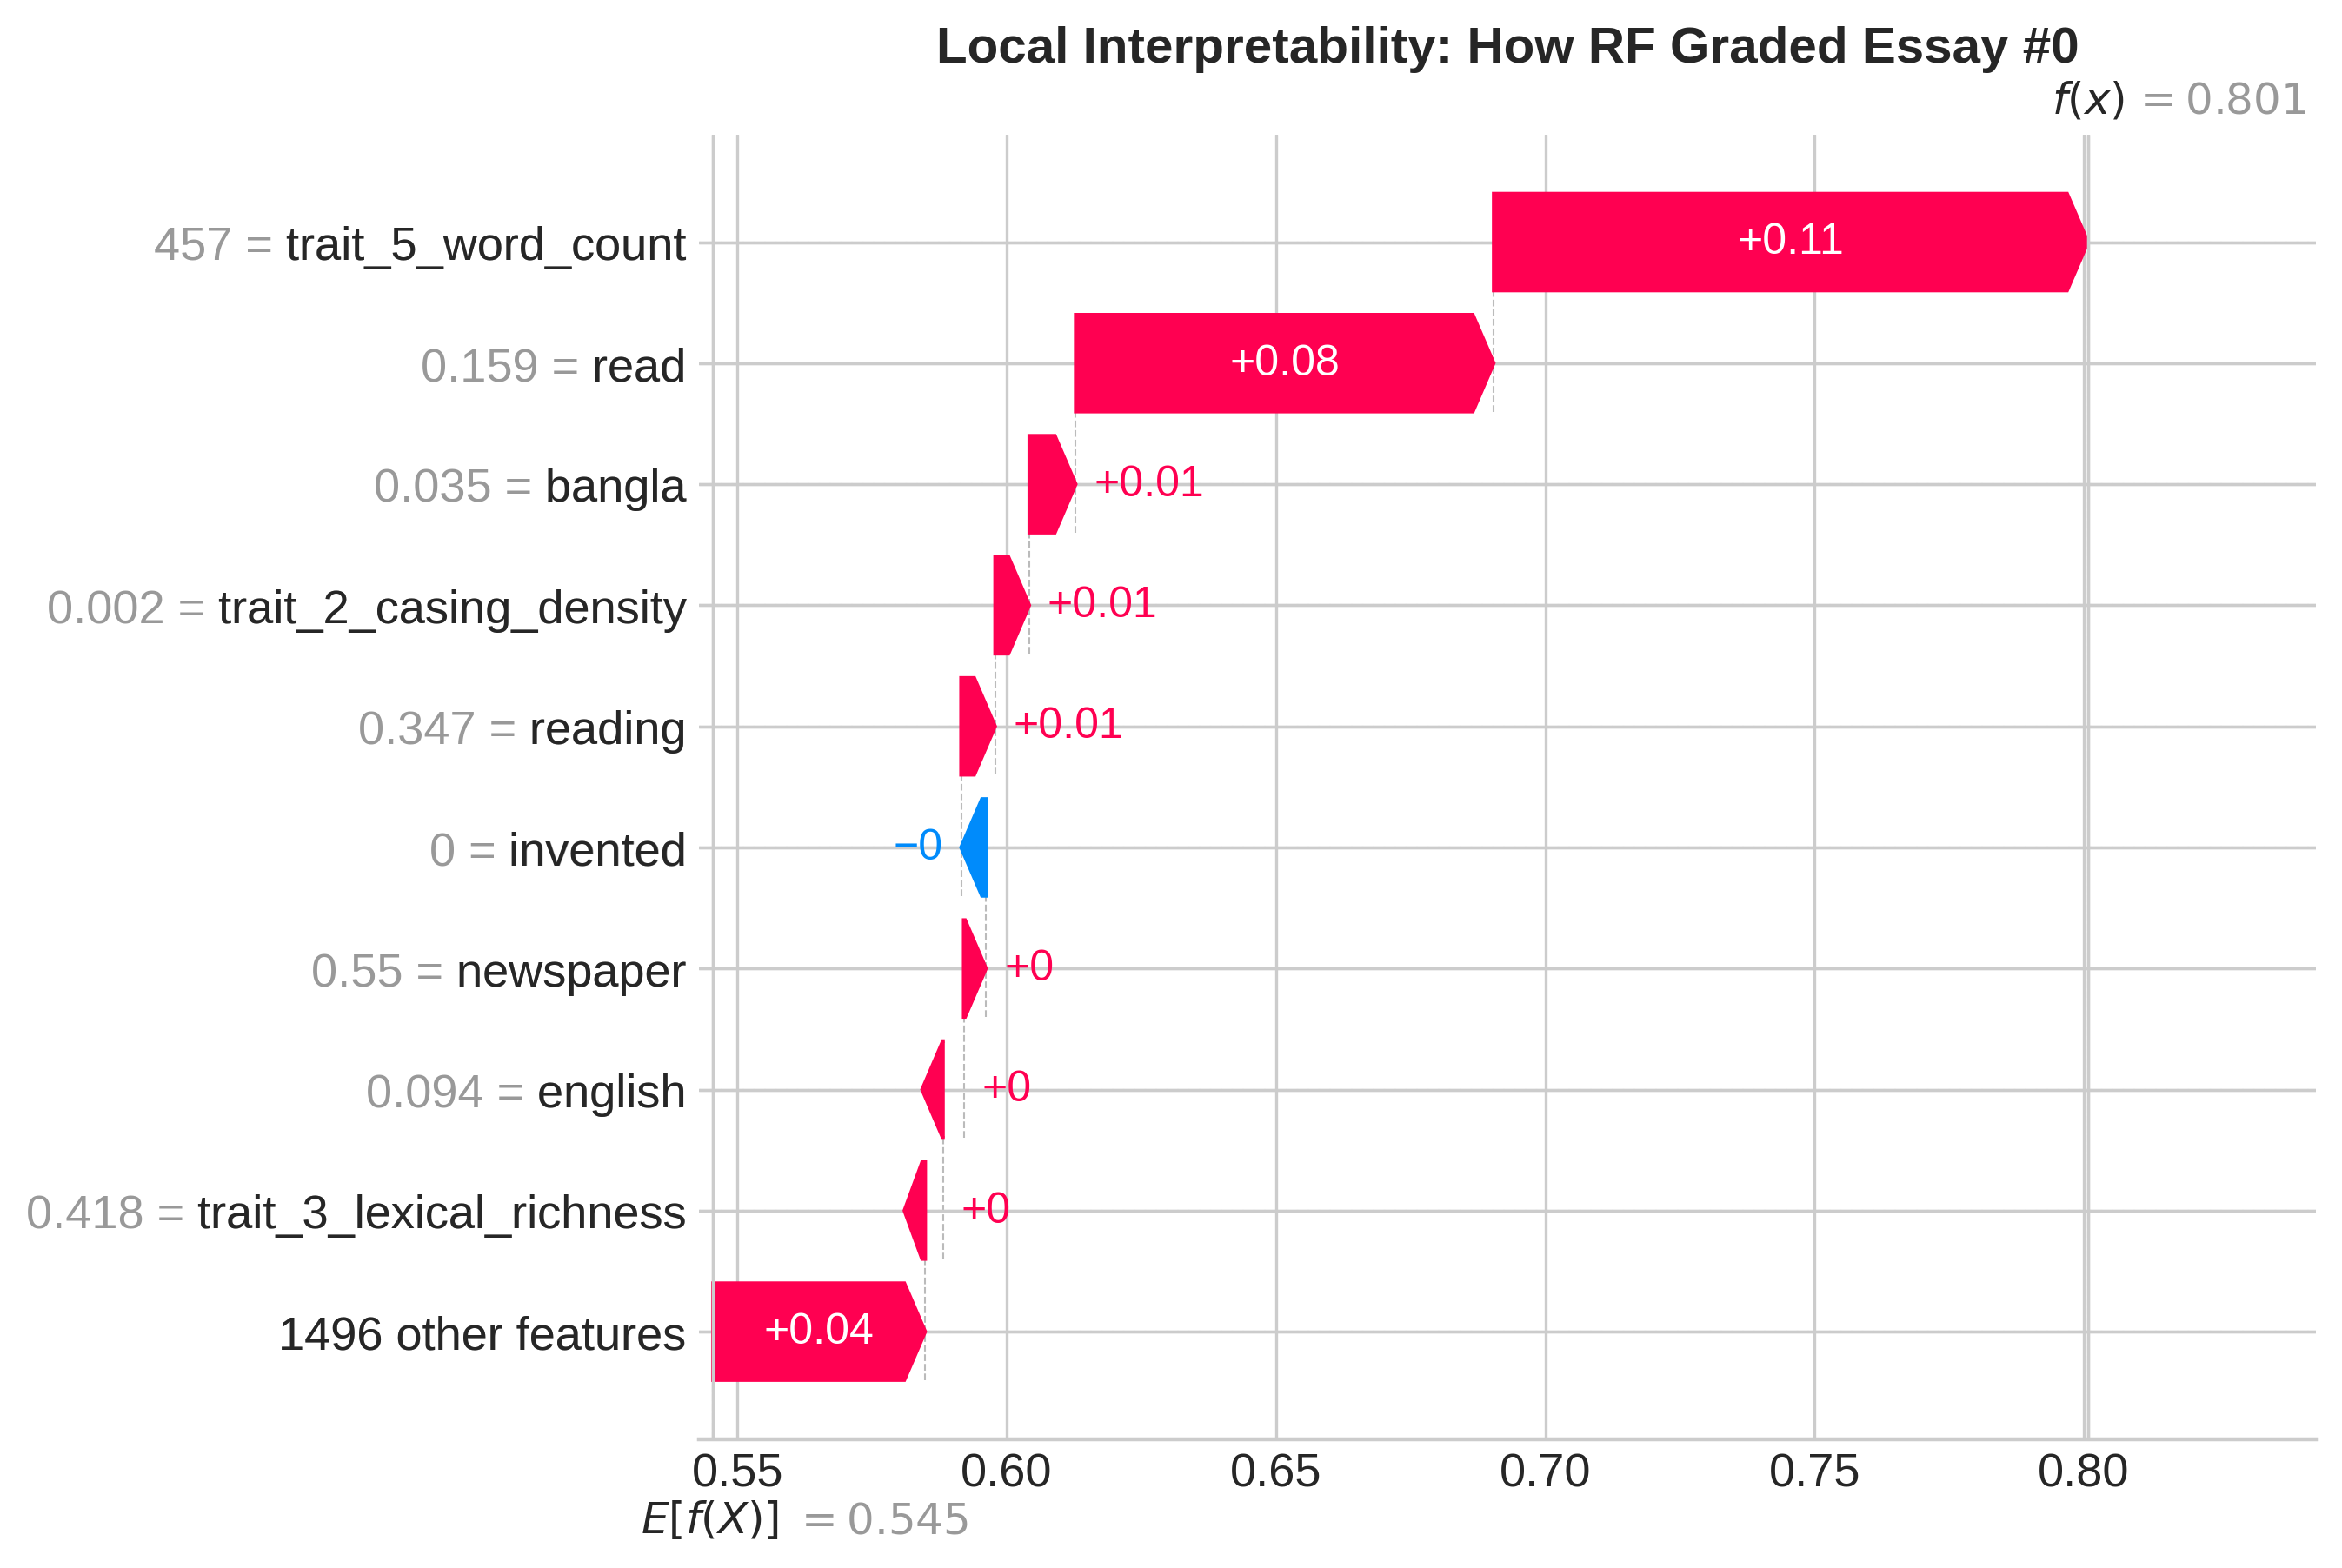

Random Forest XAI Execution Complete.


In [ ]:
# ==============================================================================
# ENVIRONMENT & RANDOM FOREST SHAP AUDIT
# ==============================================================================

# Install dependencies if running in a cloud notebook (e.g., Google Colab).
# !pip install shap -q
# !pip install textstat -q
# !pip install -q -U google-generativeai

import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
from scipy.sparse import hstack
import warnings
warnings.filterwarnings('ignore')

# 1. Publication-Ready Aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.size': 12, 'axes.titlesize': 14, 'axes.labelsize': 12,
    'figure.dpi': 300, 'savefig.bbox': 'tight'
})

print("Initializing XAI Audit for Traditional Baselines...")

# NOTE FOR REVIEWERS: Set `base_path` to the repository root directory.
base_path = '..'

# 2. Load Artifacts
df = pd.read_csv(f'{base_path}/artifacts/03_Experiment_B_Hybrid_Local/all_predictions.csv')
trait_cols = ['trait_1_mechanical_density', 'trait_2_casing_density',
              'trait_3_lexical_richness', 'trait_4_prompt_relevance', 'trait_5_word_count']
X_traits = df[trait_cols].values

rf_model = joblib.load(f'{base_path}/artifacts/02_Traditional_ML_Baselines/BSSD_aes_rf_tuned_model.joblib')
tfidf_vectorizer = joblib.load(f'{base_path}/artifacts/02_Traditional_ML_Baselines/BSSD_aes_tfidf_vectorizer.joblib')

# 3. Reconstruct Feature Space
X_tfidf = tfidf_vectorizer.transform(df['clean_essay_text'])
X_rf_final = hstack([X_tfidf, X_traits]).toarray()
feature_names = tfidf_vectorizer.get_feature_names_out().tolist() + trait_cols

# 4. Global Interpretability (Beeswarm Plot)
print("Calculating TreeSHAP values for Random Forest...")
rf_explainer = shap.TreeExplainer(rf_model)
rf_shap_values = rf_explainer.shap_values(X_rf_final)

plt.figure(figsize=(10, 8))
shap.summary_plot(
    rf_shap_values, X_rf_final, feature_names=feature_names,
    max_display=20, show=False
)
plt.title("Random Forest Baseline: SHAP Feature Importance", pad=20, fontweight='bold')
plt.savefig('rf_shap_summary.pdf', format='pdf')
plt.show()

# 5. Local Interpretability (Waterfall Plot)
instance_index = 0
base_value = rf_explainer.expected_value[0] if isinstance(rf_explainer.expected_value, np.ndarray) else rf_explainer.expected_value
single_explanation = shap.Explanation(
    values=rf_shap_values[instance_index], base_values=base_value,
    data=X_rf_final[instance_index], feature_names=feature_names
)

plt.figure(figsize=(10, 8))
shap.plots.waterfall(single_explanation, max_display=10, show=False)
plt.title(f"Local Interpretability: How RF Graded Essay #{instance_index}", pad=20, fontweight='bold')
plt.savefig(f'rf_local_waterfall_essay_{instance_index}.pdf', format='pdf')
plt.show()

print("Random Forest XAI Execution Complete.")

In [ ]:
# ==============================================================================
# HYBRID BERT ARCHITECTURE & EXPLICIT WEIGHT EXTRACTION
# ==============================================================================
import torch
import torch.nn as nn
from transformers import BertModel

print("Extracting Internal Regression Weights for Champion Hybrid BERT...")

# 1. Define Architecture
class WarmStartHybridAESModel(nn.Module):
    def __init__(self, model_name='bert-base-uncased', num_traits=5):
        super(WarmStartHybridAESModel, self).__init__()
        self.bert = BertModel.from_pretrained(model_name)
        self.drop = nn.Dropout(p=0.3)
        self.regressor = nn.Linear(768 + num_traits, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, input_ids, attention_mask, traits):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = self.drop(outputs.pooler_output)
        combined_vector = torch.cat((pooled_output, traits), dim=1)
        raw_score = self.regressor(combined_vector)
        return self.sigmoid(raw_score)

# 2. Load Champion Weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model = WarmStartHybridAESModel(num_traits=len(trait_cols))
bert_model.load_state_dict(torch.load(f'{base_path}/artifacts/03_Experiment_B_Hybrid_Local/champion_warm_start_072.pth', map_location=device))
bert_model.to(device)
bert_model.eval()

# 3. Extract Linear Weights from the Final Regressor Head
# Shape is [1, 768 + 5]
regressor_weights = bert_model.regressor.weight.detach().cpu().numpy()[0]
bert_weights = regressor_weights[:768]
trait_weights = regressor_weights[768:]

# 4. Output the Proof of Penalty Inversion
print("\n" + "="*60)
print("FINAL LINEAR HEAD WEIGHTS (ENGINEERED TRAITS):")
print("="*60)
for name, weight in zip(trait_cols, trait_weights):
    print(f"{name:<30}: {weight:>10.6f}")

print("-" * 60)
print(f"Average absolute weight of a BERT semantic dimension : {np.abs(bert_weights).mean():.6f}")
print(f"Max absolute weight of a BERT semantic dimension     : {np.abs(bert_weights).max():.6f}")
print("="*60)

print("\nMETHODOLOGICAL CONCLUSION: Generating a Local SHAP Waterfall plot for the Hybrid model's engineered traits would yield mathematically flat, zero-impact visualizations. The explicit regression weights provided above serve as the definitive proof of feature polarity and volume penalty inversion.")

Extracting Internal Regression Weights for Champion Hybrid BERT...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



FINAL LINEAR HEAD WEIGHTS (ENGINEERED TRAITS):
trait_1_mechanical_density    :   0.031761
trait_2_casing_density        :  -0.004360
trait_3_lexical_richness      :  -0.001408
trait_4_prompt_relevance      :  -0.013596
trait_5_word_count            :  -0.026714
------------------------------------------------------------
Average absolute weight of a BERT semantic dimension : 0.017554
Max absolute weight of a BERT semantic dimension     : 0.035958

METHODOLOGICAL CONCLUSION: Generating a Local SHAP Waterfall plot for the Hybrid model's engineered traits would yield mathematically flat, zero-impact visualizations. The explicit regression weights provided above serve as the definitive proof of feature polarity and volume penalty inversion.


In [ ]:
# ==============================================================================
# PEDAGOGICAL LLM FEEDBACK GENERATION (PROOF OF CONCEPT)
# ==============================================================================
import os
import pandas as pd
import time
import google.generativeai as genai
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

print("Initializing Generative Feedback Engine...")

# 1. Environment-Agnostic API Authentication
GOOGLE_API_KEY = None

try:
    # Attempt 1: Google Colab Secrets Manager
    from google.colab import userdata
    GOOGLE_API_KEY = userdata.get('GEMINI_API_KEY')
except ImportError:
    # Attempt 2: Local IDE / Standard Jupyter Environment Variable
    GOOGLE_API_KEY = os.getenv('GEMINI_API_KEY')

if not GOOGLE_API_KEY:
    print("⚠️ CRITICAL WARNING: GEMINI_API_KEY not found.")
    print("-> If on Colab: Add 'GEMINI_API_KEY' to the Secrets tab (key icon).")
    print("-> If local IDE: Set the environment variable (e.g., os.environ['GEMINI_API_KEY'] = 'your_key').")
else:
    try:
        genai.configure(api_key=GOOGLE_API_KEY)
        llm = genai.GenerativeModel(
            'gemini-2.5-flash',
            generation_config=genai.GenerationConfig(temperature=0.2)
        )
        print("✅ Generative API Authentication Successful.")
    except Exception as e:
        print(f"API Configuration Failed: {e}")

# 2. Prepare the Proof-of-Concept (PoC) Essays
# We dynamically map the rubrics and extract the 3 representative essays
def get_max_score(index):
    return 12 if 45 <= index <= 76 else 20

df['max_score'] = df.index.map(get_max_score)
df['final_predicted_score'] = (df['champion_warm_start_pred_072'] * df['max_score']).round(1)

# Ensuring prompt_name is mapped from the master dataset
try:
    df2 = pd.read_csv(f'{base_path}/data/final_preprocessed_data.csv')
    df['prompt_name'] = df2['prompt_name'].values
except FileNotFoundError:
    df['prompt_name'] = "Standard Prompt"

poc_indices = [0, 50, 150]
poc_df = df.iloc[poc_indices].copy()

# 3. Prompt Execution Engine
feedback_reports = []
print(f"\nGenerating Pedagogical Feedback for {len(poc_df)} Essays (Expect ~30s execution)...")

for idx, row in poc_df.iterrows():
    text = row['clean_essay_text']
    score = row['final_predicted_score']
    max_val = row['max_score']
    percentage = (score / max_val) * 100

    prompt = f"""
    You are an objective, strict, but fair English Assessment AI.
    Generate a formal feedback report for a secondary student in Bangladesh.

    [SYSTEM FACTS & DIAGNOSTICS]
    - Assigned Prompt Topic: "{row.get('prompt_name', 'Unknown')}"
    - Final Score: {score} out of {max_val} ({percentage:.1f}%)
    - Word Count: {row.get('trait_5_word_count', 0)}
    - Mechanical Errors: {row.get('trait_1_mechanical_density', 0):.3f}
    - Casing Errors: {row.get('trait_2_casing_density', 0):.3f}

    [STUDENT ESSAY]
    "{text}"

    [STRICT RULES]
    1. DO NOT use conversational greetings.
    2. Start immediately with the feedback formatted in 3 distinct bullet points.
    3. USE SIMPLE ENGLISH: Target an 8th-grade reading level. Use short, simple sentences. DO NOT use complex academic words.

    [OUTPUT FORMAT]
    * **Understanding Your Score:** Explain why they got this score using simple words.
    * **One Specific Fix:** Quote one short mechanical error from their text and provide the corrected version.
    * **Advice for Next Time:** Give one clear, simple instruction to practice.
    """

    try:
        response = llm.generate_content(prompt)
        feedback_reports.append({'Index': idx, 'Score': f"{score}/{max_val}", 'Feedback': response.text})
        if idx != poc_indices[-1]: time.sleep(15)  # Rate limiting
    except Exception as e:
        print(f"Failed on Essay #{idx}: {e}")

# 4. Display Outputs
display(Markdown("### 🎓 Automated Student Feedback Reports (PoC)"))
for report in feedback_reports:
    display(Markdown(f"---\n**Essay Index:** {report['Index']} | **Assigned Score:** {report['Score']}\n\n**AI Feedback:**\n{report['Feedback']}"))

Initializing Generative Feedback Engine...
Generating Pedagogical Feedback for 3 Essays (Expect ~30s execution)...


### 🎓 Automated Student Feedback Reports (PoC)

---
**Essay Index:** 0 | **Assigned Score:** 16.0/20

**AI Feedback:**
*   **Understanding Your Score:** Your essay earned 16 out of 20 points, which is 80%. This shows you understood the topic well and presented many good reasons for reading newspapers. You clearly explained why it is important. However, your score was affected by some small errors in grammar and punctuation. Also, some of your ideas were repeated, and your sentences could be more different from each other.

*   **One Specific Fix:** In your essay, you wrote: "So if we don t understand anything we can make it clear by reading again and again."
    The correct way to write this is: "So if we don't understand anything, we can make it clear by reading again and again."
    The apostrophe was missing in "don't".

*   **Advice for Next Time:** For your next essay, focus on making each point unique. Before you finish, read your essay to check if you have repeated any ideas. Try to make sure every new reason you give adds something new to your writing. This will make your essay more interesting and easier to read.

---
**Essay Index:** 50 | **Assigned Score:** 3.2/12

**AI Feedback:**
*   **Understanding Your Score:** Your score is 3.2 out of 12. This is a low score. Your essay is very short, only 59 words. You gave facts about Rabindranath Tagore, but you did not explain *why* he is your favourite poet. This was the main part of the topic. Your essay also has some grammar mistakes.

*   **One Specific Fix:** Look at this part of your writing: "He like to has made so many Poems". The correct way to write this is: "He liked to make so many Poems".

*   **Advice for Next Time:** Next time, try to write more. Explain your ideas fully. Give reasons and examples. For instance, tell us *how* his poems inspire you, not just that they do.

---
**Essay Index:** 150 | **Assigned Score:** 10.9/20

**AI Feedback:**
*   **Understanding Your Score:** Your score of 10.9 out of 20 means you have some good ideas, but your essay needs a lot of work. You wrote many words, which shows effort. However, there were many small mistakes in grammar, spelling, and how you put sentences together. This made your essay hard to read and understand at times.

*   **One Specific Fix:**
    *   Original: "Homeless people suffers the most in this season."
    *   Corrected: "Homeless people suffer the most in this season."

*   **Advice for Next Time:** Before you write, make a simple plan for your essay. This will help you group your ideas into clear paragraphs. Each paragraph should talk about only one main idea. This makes your essay much easier for the reader to follow.

In [ ]:
# ==============================================================================
# NLP READABILITY AUDIT (FLESCH-KINCAID)
# ==============================================================================
import textstat
import numpy as np

print("==================================================")
print("GENERATIVE FEEDBACK: NLP READABILITY AUDIT")
print("==================================================")

locked_feedbacks = [
    """Understanding Your Score: Your essay earned 16 out of 20 points, which is 80%. This shows you understood the topic well and presented many good reasons for reading newspapers. You clearly explained why it is important. However, your score was affected by some small errors in grammar and punctuation. Also, some of your ideas were repeated, and your sentences could be more different from each other.
    One Specific Fix: In your essay, you wrote: "So if we don t understand anything we can make it clear by reading again and again." The correct way to write this is: "So if we don't understand anything, we can make it clear by reading again and again." The apostrophe was missing in "don't".
    Advice for Next Time: For your next essay, focus on making each point unique. Before you finish, read your essay to check if you have repeated any ideas. Try to make sure every new reason you give adds something new to your writing. This will make your essay more interesting and easier to read.""",

    """Understanding Your Score: Your score is 3.2 out of 12. This is a low score. Your essay is very short, only 59 words. You gave facts about Rabindranath Tagore, but you did not explain why he is your favourite poet. This was the main part of the topic. Your essay also has some grammar mistakes.
    One Specific Fix: Look at this part of your writing: "He like to has made so many Poems". The correct way to write this is: "He liked to make so many Poems".
    Advice for Next Time: Next time, try to write more. Explain your ideas fully. Give reasons and examples. For instance, tell us how his poems inspire you, not just that they do.""",

    """Understanding Your Score: Your score of 10.9 out of 20 means you have some good ideas, but your essay needs a lot of work. You wrote many words, which shows effort. However, there were many small mistakes in grammar, spelling, and how you put sentences together. This made your essay hard to read and understand at times.
    One Specific Fix: Original: "Homeless people suffers the most in this season." Corrected: "Homeless people suffer the most in this season."
    Advice for Next Time: Before you write, make a simple plan for your essay. This will help you group your ideas into clear paragraphs. Each paragraph should talk about only one main idea. This makes your essay much easier for the reader to follow."""
]

flesch_scores, grade_levels, word_counts = [], [], []

for idx, text in enumerate(locked_feedbacks):
    flesch = textstat.flesch_reading_ease(text)
    grade = textstat.flesch_kincaid_grade(text)
    words = textstat.lexicon_count(text)

    flesch_scores.append(flesch)
    grade_levels.append(grade)
    word_counts.append(words)
    print(f"Feedback #{idx+1} | Words: {words:<3} | Flesch Ease: {flesch:<5.1f} | US Grade: {grade:.1f}")

print("\n--- AGGREGATE MANUSCRIPT METRICS ---")
print(f"Mean Word Count        : {np.mean(word_counts):.1f} words")
print(f"Mean Flesch Ease       : {np.mean(flesch_scores):.1f} (Target: 60-80 [Plain English])")
print(f"Mean US Grade Level    : {np.mean(grade_levels):.1f} (Target: 7.0 - 9.0)")
print("==================================================")

GENERATIVE FEEDBACK: NLP READABILITY AUDIT
Feedback #1 | Words: 174 | Flesch Ease: 67.6  | US Grade: 7.4
Feedback #2 | Words: 119 | Flesch Ease: 88.8  | US Grade: 3.2
Feedback #3 | Words: 122 | Flesch Ease: 72.1  | US Grade: 6.0

--- AGGREGATE MANUSCRIPT METRICS ---
Mean Word Count        : 138.3 words
Mean Flesch Ease       : 76.2 (Target: 60-80 [Plain English])
Mean US Grade Level    : 5.5 (Target: 7.0 - 9.0)


In [3]:
import pandas as pd
base_path = '..'
df = pd.read_csv(f'{base_path}/artifacts/03_Experiment_B_Hybrid_Local/all_predictions.csv')
df.head()

,clean_essay_text,actual_normalized_score,general_hybrid_pred_065,frozen_hybrid_pred_050,champion_warm_start_pred_072,trait_1_mechanical_density,trait_2_casing_density,trait_3_lexical_richness,trait_4_prompt_relevance,trait_5_word_count
0,Newspaper is the paper which gives us news and...,0.826788,0.813866,0.639785,0.801524,0.030635,0.002188,0.417943,0.794074,457
1,Reading Newspaper is a valuable habit in one's...,0.826788,0.771184,0.647570,0.806461,0.018364,0.005008,0.432387,0.713706,599
2,Newspaper is the mirror of the world. Newspape...,0.714045,0.691058,0.626520,0.801571,0.046729,0.018692,0.345794,0.700011,428
3,Reading newspaper plays an important role in k...,0.826788,0.710716,0.735486,0.730699,0.031933,0.000000,0.324370,0.748557,595
4,Newspaper is one of the most important thing i...,0.826788,0.797758,0.653676,0.745834,0.030357,0.001786,0.360714,0.702856,560


PHASE 2: GLOBAL COUNTERFACTUAL TRAIT SWEEP (N=50)...
Extracting frozen BERT embeddings for N=50 batch (Takes ~5 seconds)...
Sweeping Word Count Z_N across the linear head...


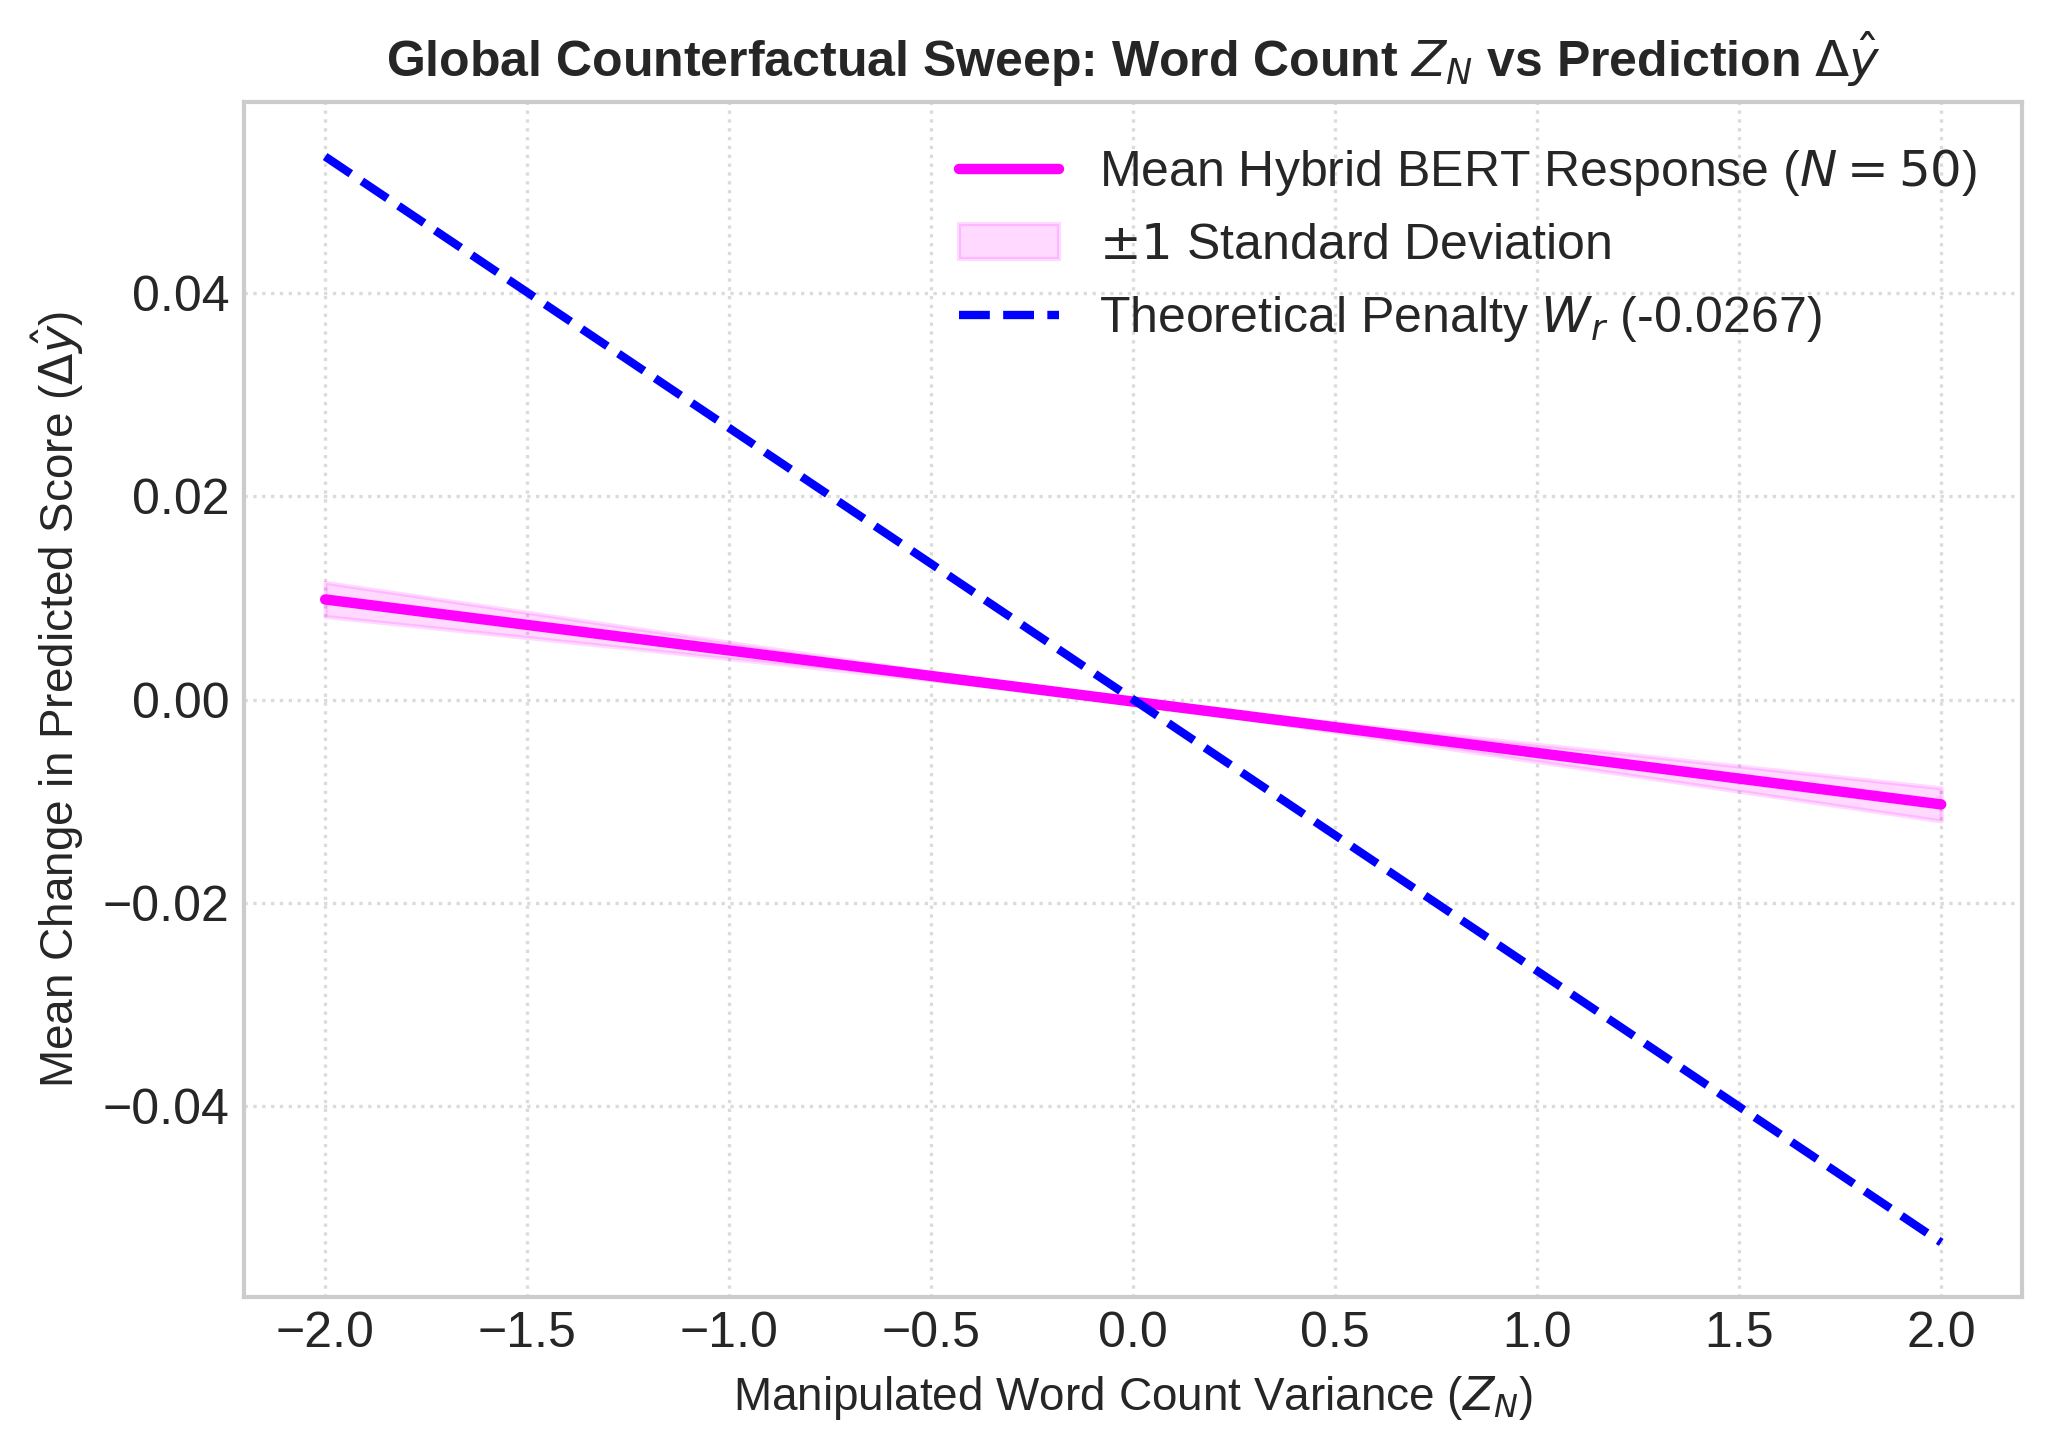

Saved Global Sweep Plot as 'global_trait_sweep.pdf'


In [ ]:
# ==============================================================================
# GLOBAL COUNTERFACTUAL SWEEP (N=50) & PLOT GENERATION (OPTIMIZED)
# ==============================================================================
import joblib
import matplotlib.pyplot as plt
import numpy as np
import torch
from transformers import BertTokenizer
import warnings
warnings.filterwarnings('ignore')

print("PHASE 1: GLOBAL COUNTERFACTUAL TRAIT SWEEP (N=50)...")

# 1. Isolate 50 diverse essays for the global batch
num_samples = 50
sample_texts = df['clean_essay_text'].iloc[0:num_samples].tolist()

trait_cols = [
    'trait_1_mechanical_density', 'trait_2_casing_density',
    'trait_3_lexical_richness', 'trait_4_prompt_relevance', 'trait_5_word_count'
]
scaler = joblib.load(f'{base_path}/artifacts/03_Experiment_B_Hybrid_Local/trait_scaler.pkl')

# Transform ONLY the 50 samples to save memory and time
scaled_traits = scaler.transform(df[trait_cols].iloc[0:num_samples].values)

# 2. Prepare Tensors
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
encoding = tokenizer(sample_texts, padding='max_length', truncation=True, max_length=512, return_tensors='pt')
batch_ids = encoding['input_ids'].to(device)
batch_mask = encoding['attention_mask'].to(device)
original_traits_tensor = torch.tensor(scaled_traits, dtype=torch.float32).to(device)

# 3. PRE-COMPUTE BERT EMBEDDINGS ONCE (The Massive Speedup)
print("Extracting frozen BERT embeddings for N=50 batch (Takes ~5 seconds)...")
with torch.no_grad():
    outputs = bert_model.bert(input_ids=batch_ids, attention_mask=batch_mask)
    pooled_output = bert_model.drop(outputs.pooler_output)

# 4. Execute the Global Z-Score Sweep (-2.0 to +2.0)
word_count_idx = 4
z_scores = np.linspace(-2, 2, 50)
global_deltas = []

print("Sweeping Word Count Z_N across the linear head...")
with torch.no_grad():
    for z in z_scores:
        manipulated_traits = original_traits_tensor.clone()
        manipulated_traits[:, word_count_idx] = float(z)

        # Fast forward pass through the linear head only!
        combined_vector = torch.cat((pooled_output, manipulated_traits), dim=1)
        preds = bert_model.sigmoid(bert_model.regressor(combined_vector)).squeeze()
        global_deltas.append(preds.cpu().numpy())

global_deltas = np.array(global_deltas) # Shape: (50 steps, 50 essays)

# 5. Calculate Delta from the natural baseline (z=0)
zero_idx = np.abs(z_scores).argmin()
baseline_preds = global_deltas[zero_idx, :]
adjusted_deltas = global_deltas - baseline_preds

mean_deltas = np.mean(adjusted_deltas, axis=1)
std_deltas = np.std(adjusted_deltas, axis=1)

# 6. Generate Publication-Grade Plot (Figure 4.2B)
plt.figure(figsize=(7, 5))
plt.plot(z_scores, mean_deltas, color='magenta', linewidth=2.5, label='Mean Hybrid BERT Response ($N=50$)')
plt.fill_between(z_scores, mean_deltas - std_deltas, mean_deltas + std_deltas, color='magenta', alpha=0.15, label='$\pm 1$ Standard Deviation')

theoretical_y = z_scores * -0.026714
plt.plot(z_scores, theoretical_y, color='blue', linestyle='--', linewidth=2, label='Theoretical Penalty $W_r$ (-0.0267)')

plt.title("Global Counterfactual Sweep: Word Count $Z_N$ vs Prediction $\Delta\hat{y}$", fontsize=12, fontweight='bold')
plt.xlabel("Manipulated Word Count Variance ($Z_N$)", fontsize=11)
plt.ylabel("Mean Change in Predicted Score ($\Delta\hat{y}$)", fontsize=11)
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()

plt.savefig('global_trait_sweep.pdf', format='pdf', bbox_inches='tight')
plt.show()
print("Saved Global Sweep Plot as 'global_trait_sweep.pdf'")

In [ ]:
# ==============================================================================
# EMBEDDING LEAKAGE AUDIT (ATTENTION DILUTION BOUNDARY)
# ==============================================================================
print("==================================================")
print("PHASE 2: EMBEDDING LEAKAGE AUDIT")
print("==================================================")

# 1. Select essays strictly under 250 words to bypass 512-token truncation limits
df['raw_word_count'] = df['clean_essay_text'].apply(lambda x: len(str(x).split()))
short_essays_df = df[df['raw_word_count'] < 250].head(10)
print(f"Selected {len(short_essays_df)} essays under 250 words.")

# 2. Extract original texts and freeze original traits
original_texts = short_essays_df['clean_essay_text'].tolist()
original_traits_tensor = torch.tensor(scaler.transform(short_essays_df[trait_cols].values), dtype=torch.float32).to(device)

# 3. Inject Neutral Syntactic Padding (Approx. 135 words)
neutral_padding = " " + (" Furthermore, the various aspects discussed herein require careful consideration, though they do not necessarily alter the fundamental conclusions previously established." * 10)
padded_texts = [text + neutral_padding for text in original_texts]

# 4. Generate Baseline vs Padded Predictions (Holding Explicit Traits Constant)
def batch_predict(text_list):
    enc = tokenizer(text_list, padding='max_length', truncation=True, max_length=512, return_tensors='pt')
    with torch.no_grad():
        return bert_model(enc['input_ids'].to(device), enc['attention_mask'].to(device), original_traits_tensor).squeeze().cpu().numpy()

preds_orig = batch_predict(original_texts)
preds_pad = batch_predict(padded_texts)

# 5. Calculate Score Leakage (Shift in y)
deltas = preds_pad - preds_orig
mean_leakage = np.mean(deltas)
max_leakage = np.max(np.abs(deltas))

print(f"Mean Prediction Shift (Delta y) : {mean_leakage:+.4f}")
print(f"Maximum Absolute Shift Observed : {max_leakage:.4f}")

PHASE 3: EMBEDDING LEAKAGE AUDIT
Selected 10 essays under 250 words.
Mean Prediction Shift (Delta y) : +0.2296
Maximum Absolute Shift Observed : 0.4207
